# Práctica 2

Manuel Suano Gallardo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

separador = "######################################"

___
## Análisis exploratorio de los datos

In [2]:
# Carga de datos
datos = pd.read_csv('wdbc.data', sep=',', header=None)

target = datos[1]

# Eliminado de las columnas innecesarias
datos.drop(columns=[0,1], inplace=True)

# Nombrado de las columnas
columnas = ['radio', 'textura', 'perimetro', 'area', 'suavidad', 'compactitud', 
			'concavidad', 'puntos_concavos', 'simetria', 'dimension_fractal']

datos.columns = pd.Index(np.append(
	(np.array(columnas) + '1'), [(np.array(columnas) + '2'), (np.array(columnas) + '3')]
))

# ##############################################################################
# Descipción estadística

print(">> Dimensiones", datos.shape)

print(separador)

print(">> Información básica")
print(datos.info())

print(separador)

print(">> Descripción estadística")

datos_descr = datos.describe().T

datos_descr['IQR'] = datos_descr['75%'] - datos_descr['25%']
datos_descr['mode'] = datos.mode().iloc[0]
datos_descr['asimetria'] = datos.skew()
datos_descr['curtosis'] = datos.kurtosis()

columnas_visibles = ['mean', 'std', 'mode', '50%', 'max', 'min', 'IQR', 'asimetria', 'curtosis']

print(datos_descr[columnas_visibles].round(3))	

print(separador)

print(target.value_counts())

>> Dimensiones (569, 30)
######################################
>> Información básica
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radio1              569 non-null    float64
 1   textura1            569 non-null    float64
 2   perimetro1          569 non-null    float64
 3   area1               569 non-null    float64
 4   suavidad1           569 non-null    float64
 5   compactitud1        569 non-null    float64
 6   concavidad1         569 non-null    float64
 7   puntos_concavos1    569 non-null    float64
 8   simetria1           569 non-null    float64
 9   dimension_fractal1  569 non-null    float64
 10  radio2              569 non-null    float64
 11  textura2            569 non-null    float64
 12  perimetro2          569 non-null    float64
 13  area2               569 non-null    float64
 14  suavidad2           569 non-nul

In [3]:
datos_descr[columnas_visibles].round(3)

,mean,std,mode,50%,max,min,IQR,asimetria,curtosis
radio1,14.127,3.524,12.340,13.370,28.110,6.981,4.080,0.942,0.846
textura1,19.290,4.301,14.930,18.840,39.280,9.710,5.630,0.650,0.758
perimetro1,91.969,24.299,82.610,86.240,188.500,43.790,28.930,0.991,0.972
area1,654.889,351.914,512.200,551.100,2501.000,143.500,362.400,1.646,3.652
suavidad1,0.096,0.014,0.101,0.096,0.163,0.053,0.019,0.456,0.856
compactitud1,0.104,0.053,0.115,0.093,0.345,0.019,0.065,1.190,1.650
concavidad1,0.089,0.080,0.000,0.062,0.427,0.000,0.101,1.401,1.999
puntos_concavos1,0.049,0.039,0.000,0.034,0.201,0.000,0.054,1.171,1.067
simetria1,0.181,0.027,0.160,0.179,0.304,0.106,0.034,0.726,1.288
dimension_fractal1,0.063,0.007,0.057,0.062,0.097,0.050,0.008,1.304,3.006


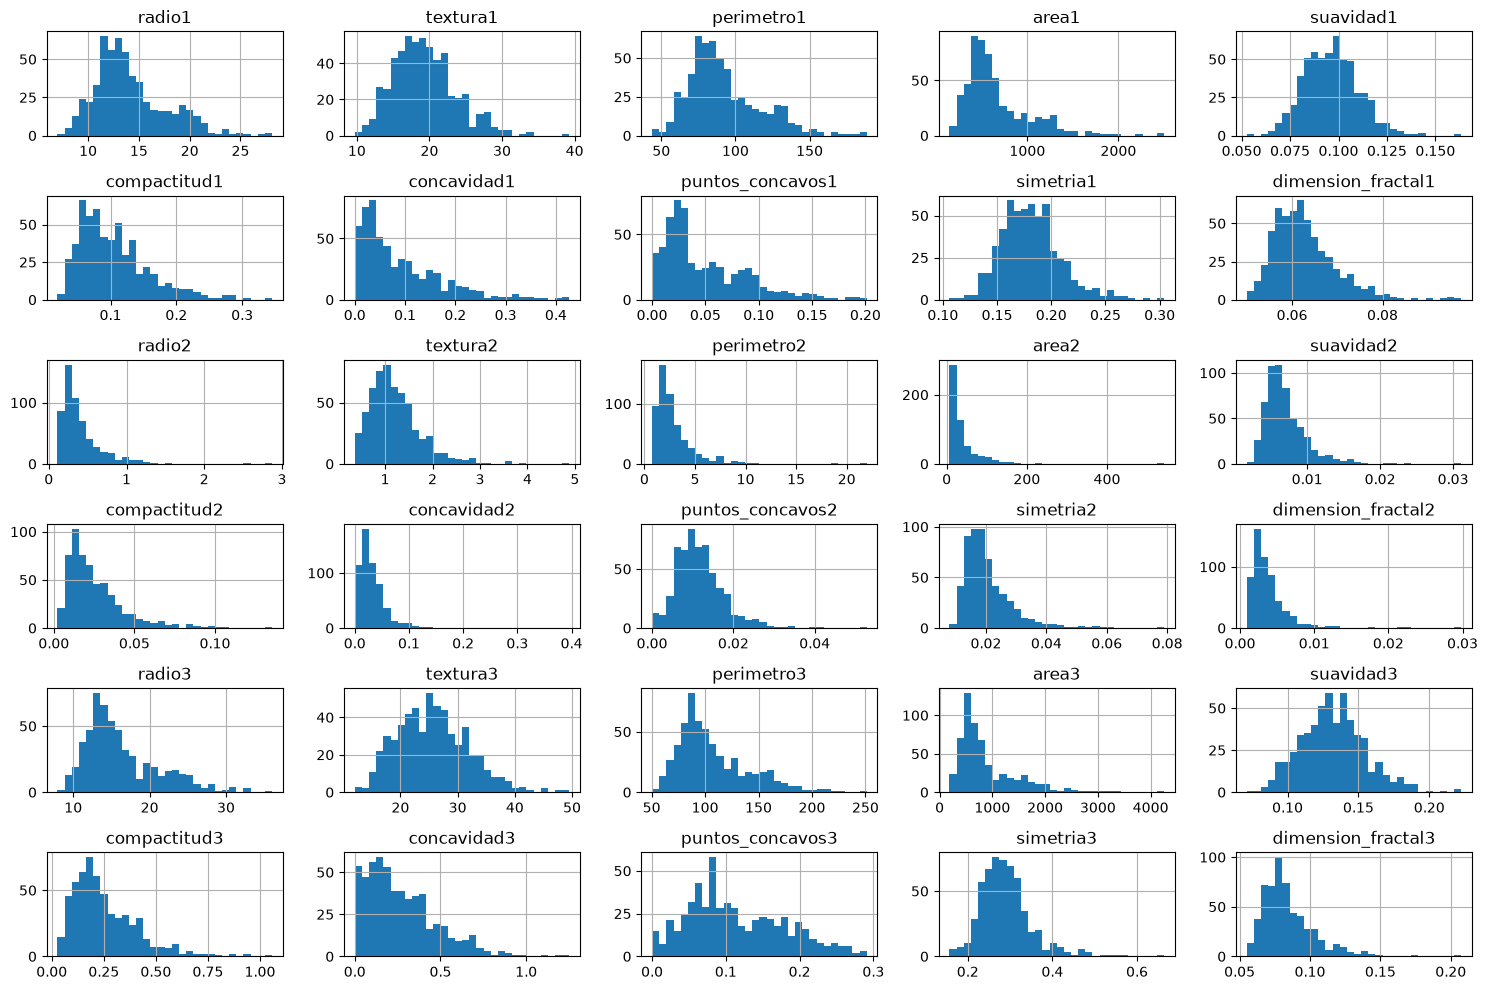

In [4]:
# Histogramas de las variables
datos.hist(figsize=(15,10), bins=30)
plt.tight_layout()
plt.show()

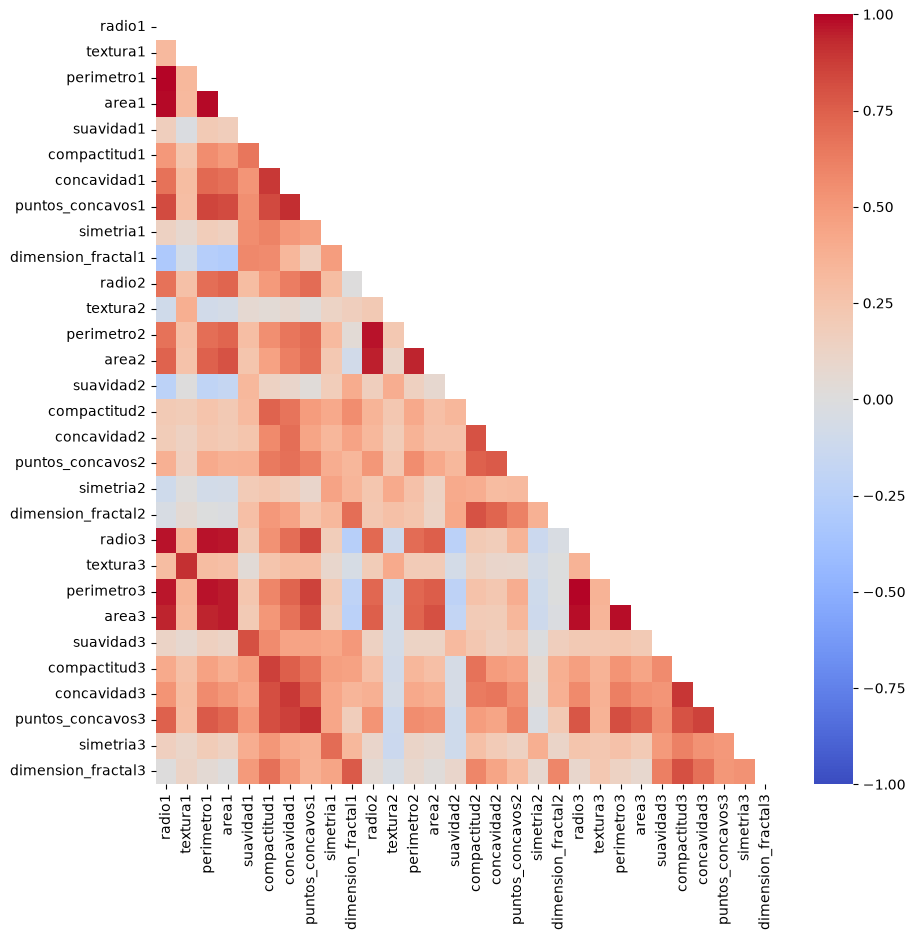

In [5]:
matriz_corr = datos.corr()

plt.figure(figsize=(10,10))
sns.heatmap(
    matriz_corr, fmt=".2f", cmap='coolwarm', 
    vmin=-1, vmax=1, mask = np.triu(np.ones_like(matriz_corr))
)
plt.show()

In [6]:
class Preprocesado():
	escalador = StandardScaler()

	@classmethod
	def aplicar_log(cls, datos, min_0 = []):
		"""
		Aplica la transformación del logaritmo. Suma 0.1 a las columnas que se 
		indiquen.
		"""
		if len(min_0) > 1:
			datos[min_0] = datos[min_0] + 1

		return datos.apply(lambda x : np.log(x))

	@classmethod
	def aplicar_escalador_normal(cls, datos):
		"""
		Aplica un escalado basado en una distribución normal a los datos
		"""
		return cls.escalador.fit_transform(datos)

In [7]:
# 1. aplicar transformación del log
datos = Preprocesado.aplicar_log(
    datos, 
    datos_descr.index[np.nonzero(datos_descr['min'] == 0)]
)

# 2. aplicar escalador
datos = Preprocesado.aplicar_escalador_normal(datos)

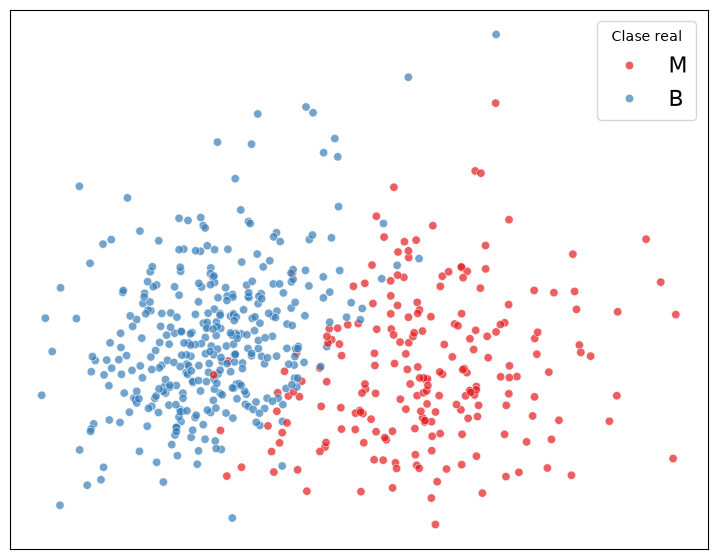

In [12]:
pca = PCA(n_components=2, random_state=0)
datos_pca = pca.fit_transform(datos)

datos_pca = pd.DataFrame(data=datos_pca, columns=['x', 'y'])
datos_pca['objetivo'] = target

plt.figure(figsize=(9, 7))
sns.scatterplot(
    x		= 'x',
    y		= 'y',
    hue		= 'objetivo',
    palette	= 'Set1',
    data	= datos_pca,
    alpha	= 0.7,
    edgecolor = 'w',
)

plt.legend(title='Clase real', loc='upper right', fontsize=16)
plt.ylabel('')
plt.xlabel('')
plt.xticks([])
plt.yticks([])
plt.show()

___
## Entrenamiento y evaluación de los modelos

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Almacenamiento de los resultados obtenidos en cada métrica por modelo
resultados = {
    'kmedias' 	: {
        'sil' : [], 'ch' : [], 'db' : []
	},
    'gmm'		: {
        'sil' : [], 'ch' : [], 'db' : []
	},
    'jerarquico' : {
        'sil' : [], 'ch' : [], 'db' : []
	}
}

for k in range(2,11):

	kmedias = KMeans(n_clusters=k, random_state=0)
	gmm = GaussianMixture(n_components=k, random_state=0)
	jerarquico = AgglomerativeClustering(n_clusters=k, linkage='average')

	# Predicciones
	y_pred_kmedias = kmedias.fit_predict(datos)
	y_pred_gmm = gmm.fit_predict(datos)
	y_pred_jerarquico = jerarquico.fit_predict(datos)

	# Calculo metricas
	resultados['kmedias']['sil'].append(silhouette_score(datos, y_pred_kmedias, random_state=0))
	resultados['kmedias']['ch'].append(calinski_harabasz_score(datos, y_pred_kmedias))
	resultados['kmedias']['db'].append(davies_bouldin_score(datos, y_pred_kmedias))

	resultados['gmm']['sil'].append(silhouette_score(datos, y_pred_gmm, random_state=0))
	resultados['gmm']['ch'].append(calinski_harabasz_score(datos, y_pred_gmm))
	resultados['gmm']['db'].append(davies_bouldin_score(datos, y_pred_gmm))

	resultados['jerarquico']['sil'].append(silhouette_score(datos, y_pred_jerarquico, random_state=0))
	resultados['jerarquico']['ch'].append(calinski_harabasz_score(datos, y_pred_jerarquico))
	resultados['jerarquico']['db'].append(davies_bouldin_score(datos, y_pred_jerarquico))


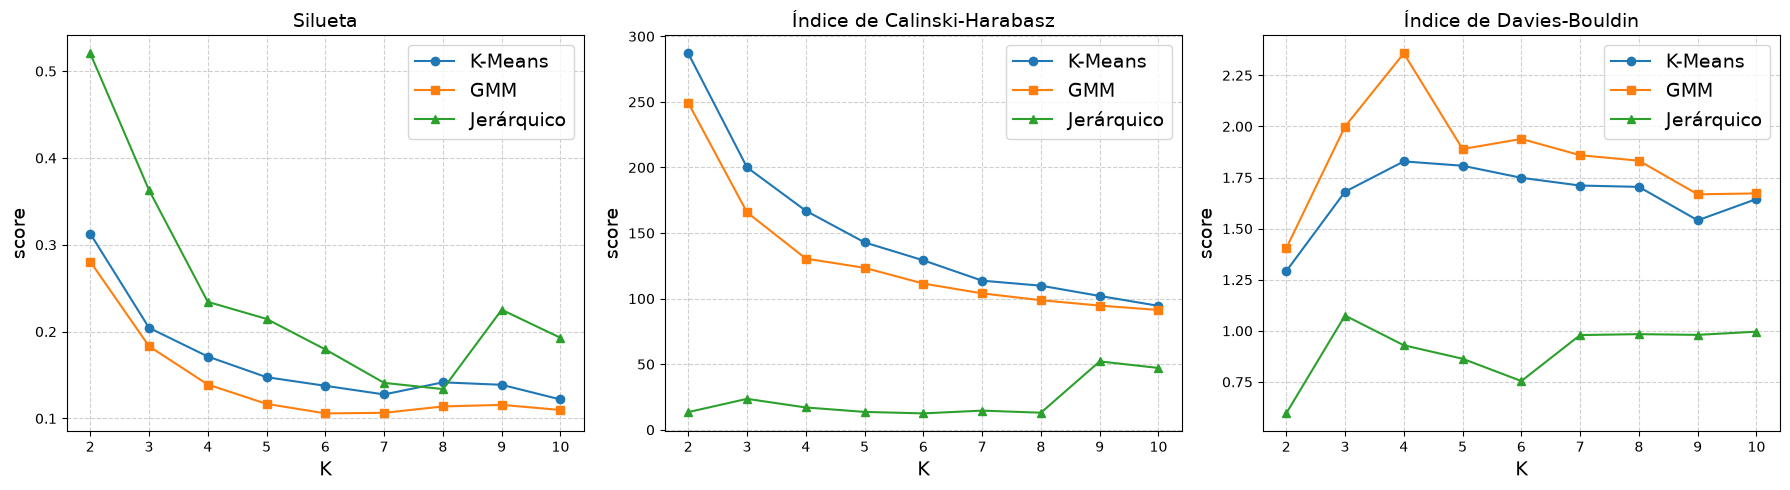

In [37]:
valores_k = list(range(2,11))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Silueta
axes[0].plot(valores_k, resultados['kmedias']['sil'], marker='o', label='K-Means')
axes[0].plot(valores_k, resultados['gmm']['sil'], marker='s', label='GMM')
axes[0].plot(valores_k, resultados['jerarquico']['sil'], marker='^', label='Jerárquico')
axes[0].set_title('Silueta', fontsize=14)
axes[0].set_xlabel('K', fontsize=14)
axes[0].set_ylabel('score', fontsize=14)
axes[0].legend(fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Coeficiente de Calinski-Harabasz
axes[1].plot(valores_k, resultados['kmedias']['ch'], marker='o', label='K-Means')
axes[1].plot(valores_k, resultados['gmm']['ch'], marker='s', label='GMM')
axes[1].plot(valores_k, resultados['jerarquico']['ch'], marker='^', label='Jerárquico')
axes[1].set_title('Índice de Calinski-Harabasz', fontsize=14)
axes[1].set_xlabel('K', fontsize=14)
axes[1].set_ylabel('score', fontsize=14)
axes[1].legend(fontsize=14)
axes[1].grid(True, linestyle='--', alpha=0.6)

# Índice de Davies-Bouldin
axes[2].plot(valores_k, resultados['kmedias']['db'], marker='o', label='K-Means')
axes[2].plot(valores_k, resultados['gmm']['db'], marker='s', label='GMM')
axes[2].plot(valores_k, resultados['jerarquico']['db'], marker='^', label='Jerárquico')
axes[2].set_title('Índice de Davies-Bouldin', fontsize=14)
axes[2].set_xlabel('K', fontsize=14)
axes[2].set_ylabel('score', fontsize=14)
axes[2].legend(fontsize=14)
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [26]:
np.argmin(resultados['jerarquico']['ch'])

np.int64(4)